#  Modelización de la volatilidad

Datos de S&P 500 Market Index (fuente: https://github.com/yashveersinghsohi/Statistical_Modeling_for_Time_Series_Forecasting)

Documentación de la librería : https://arch.readthedocs.io/en/latest/index.html

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.graphics.tsaplots as sgt
from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.metrics import mean_squared_error, mean_absolute_error

from arch import arch_model

import warnings

sns.set()
warnings.filterwarnings("ignore")
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch

## Los datos
En el archivo data.csv tenemos datos diarios dede 06/07/1994 hasta el 30/08/2019 del índice S&P 500 (SPX). "El Indice Standard & Poor's 500, más conocido como S&P500 o simplemente S&P, es un conjunto de las 500 mayores empresas que cotizan en las bolsas de Estados Unidos ponderadas según su capitalización bursátil." ([Fuente](https://www.plus500.com/es-ES/Instruments/ES/What-is-the-S&P-500~1))

Se toman los datos de cierre de los índices y se calcula el rendimiento en cada instante temporal:

$Rendimiento(t) = \frac{Cierre(t)-Cierre(t-1)}{Cierre(t-1)}$

En el set de datos, esta variable viene representada por la colunma
- spx_ret: rendimiento de las inversiones

In [26]:
file_path = "data_volatility.csv"
data = pd.read_csv(file_path)
data.Date = pd.to_datetime(data.Date)
data.set_index("Date", inplace = True)
data.dropna(inplace = True) # el primer día no tiene rendimiento

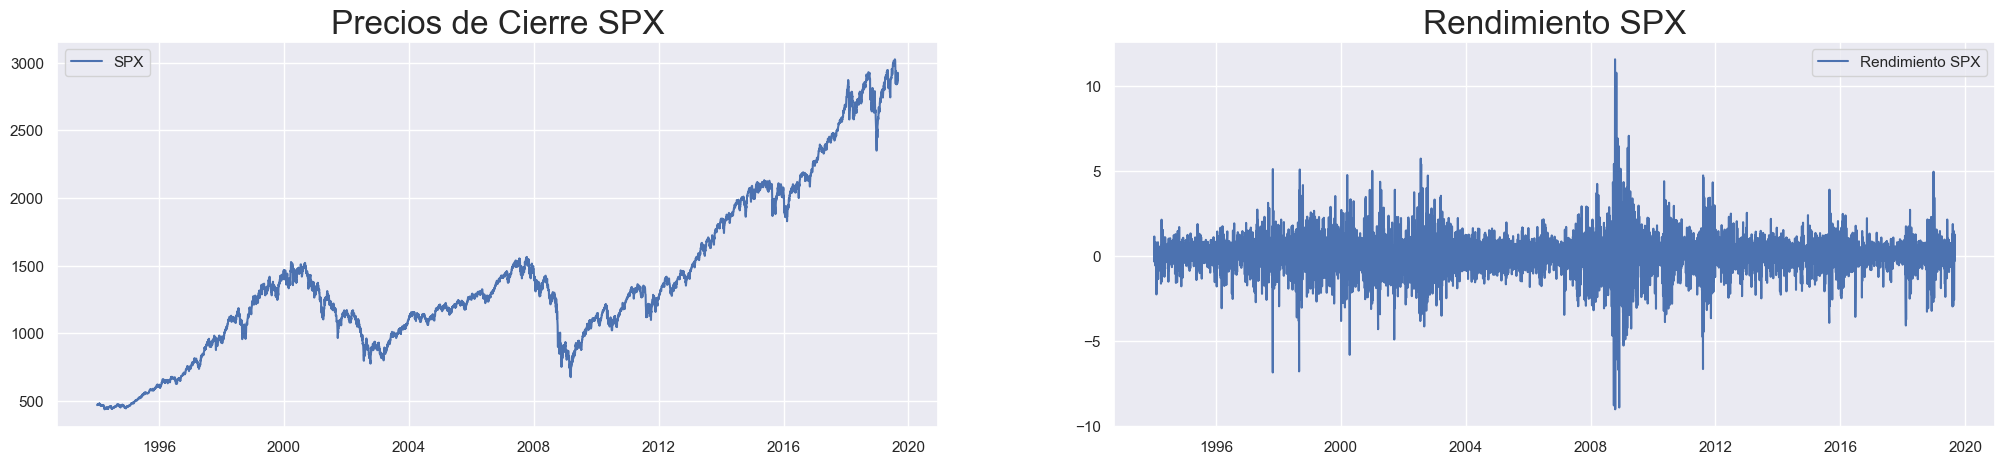

In [27]:
plt.rcParams["figure.figsize"] = (25, 5)

fig, ax = plt.subplots(1, 2)

ax[0].plot(data.spx, label = "SPX")
ax[0].set_title("Precios de Cierre SPX", size = 24)
ax[0].legend()

ax[1].plot(data.spx_ret, label = "Rendimiento SPX")
ax[1].set_title("Rendimiento SPX", size = 24)
ax[1].legend()

Añadimos otra columna con la serie al cuadrado que nos dará la representación volatilidad.

In [28]:
data["spx_vol"] = data.spx_ret.mul(data.spx_ret)

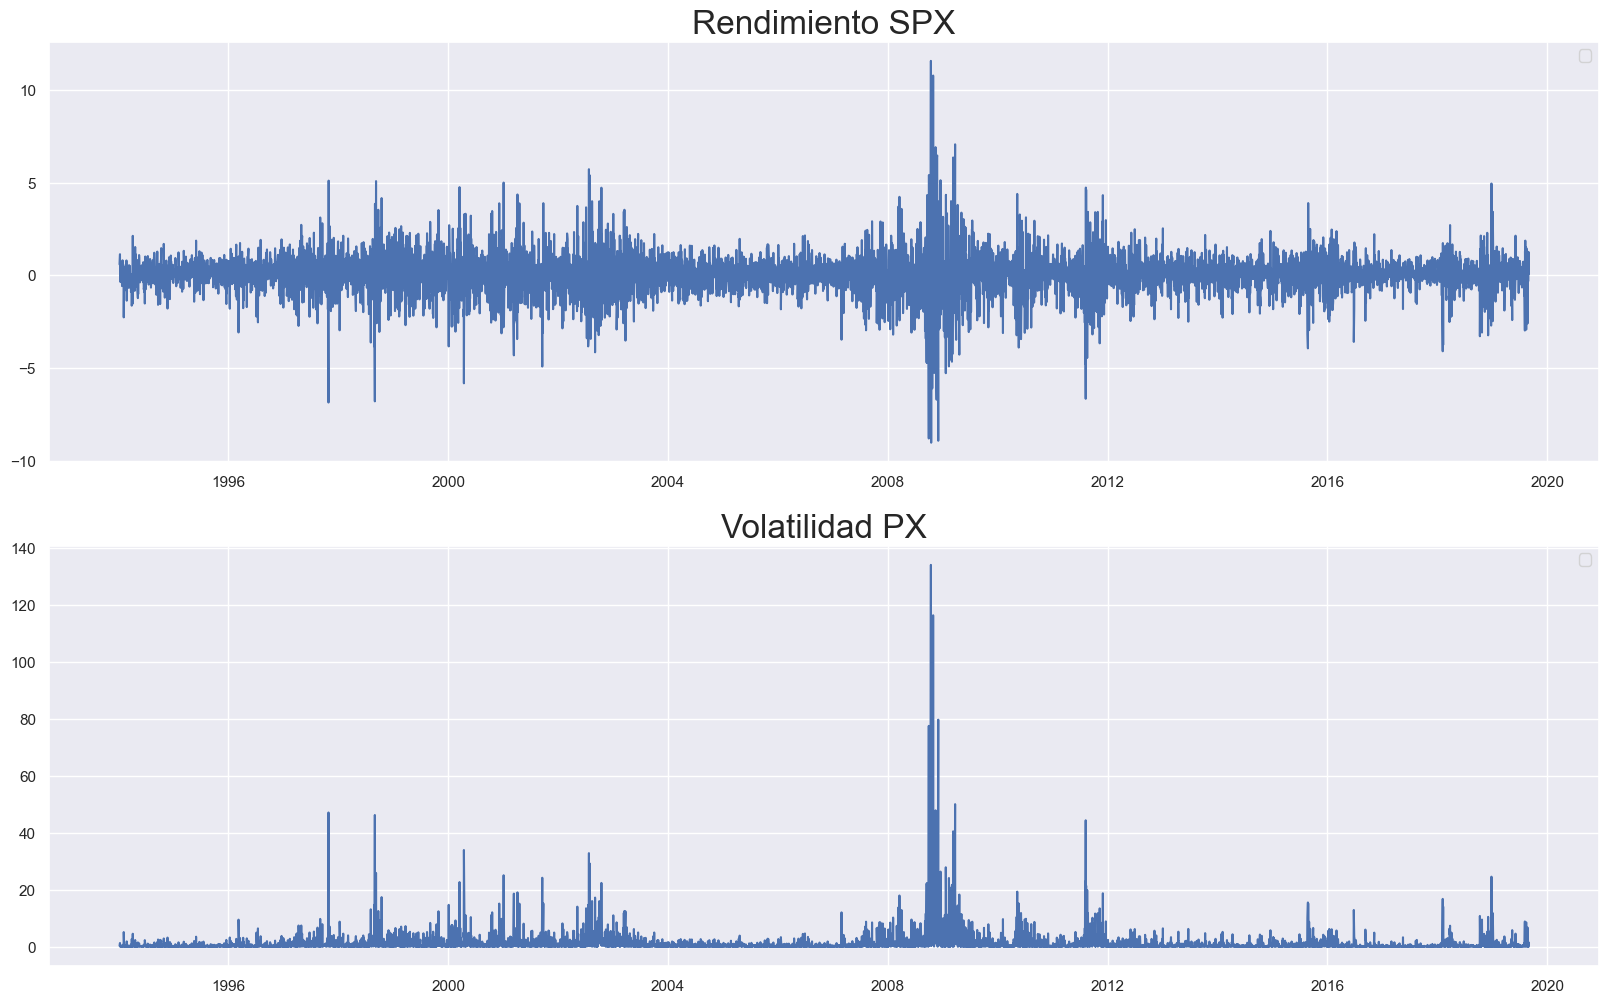

In [29]:
plt.rcParams["figure.figsize"] = (20, 12)

fig, ax = plt.subplots(2,1)

ax[0].plot(data.spx_ret)
ax[0].set_title("Rendimiento SPX", size = 24)
ax[0].legend()

ax[1].plot(data.spx_vol)
ax[1].set_title("Volatilidad PX", size = 24)
ax[1].legend()

En la última imagen se puede comprobar fácilmente cuales son los periodos de baja y alta volatilidad (periodos de mayor incertidumbre).

## Train - Test Split

In [30]:
train_df = data.loc[:"2018-12-31"]
test_df = data.loc["2019-01-01":]

## Estacionariedad y efecto ARCH

Comprobamos con los tests de raíz unitaria si el rendimiento (conjunto de entrenamiento) es estacionario en media y con el test ARCH si hay heterocedasticidad condicional.

In [31]:
adf_result = adfuller(train_df.spx_ret)
kpss_result = kpss(train_df.spx_ret)
print("ADF p-valor", adf_result[1])
print("KPSS p-valor", kpss_result[1])

ADF p-valor 7.286951578521614e-27
KPSS p-valor 0.1


In [32]:
lm_test = het_arch(train_df.spx_ret)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 1512.4086
P-valor LM: 0.0000
Estadístico F: 196.7049
P-valor F: 0.0000


ADF rechaza la raíz unitaria (p < 0.05) y KPSS no rechaza la estacionariedad (p > 0.05): el rendimiento es estacionario en media. Sin embargo, el test ARCH da un p-valor < 0.05, por lo que la serie presenta heterocedasticidad (la varianza no es constante) y tiene sentido modelizar la volatilidad con un modelo ARCH/GARCH.

## Residuo de la serie

El precio de cierre tiene tendencia. Para obtener el residuo eliminamos la tendencia mediante diferenciación (igual que en el ejemplo del residuo), tras comprobar que no hay componente estacional.

Text(0.5, 1.0, 'Residuo (serie diferenciada)')

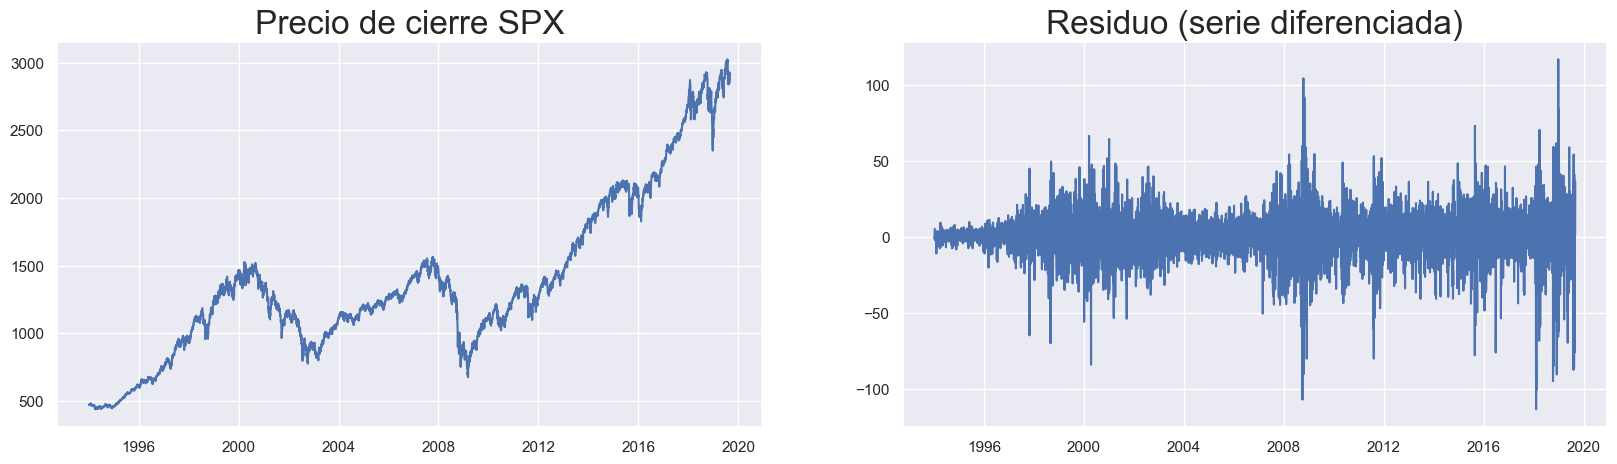

In [33]:
residuo = data.spx.diff().dropna()
train_res = residuo.loc[:"2018-12-31"]
test_res = residuo.loc["2019-01-01":]

fig, ax = plt.subplots(1, 2, figsize = (20, 5))
ax[0].plot(data.spx)
ax[0].set_title("Precio de cierre SPX", size = 24)
ax[1].plot(residuo)
ax[1].set_title("Residuo (serie diferenciada)", size = 24)

In [34]:
adf_result = adfuller(train_res)
kpss_result = kpss(train_res)
print("ADF p-valor", adf_result[1])
print("KPSS p-valor", kpss_result[1])

lm_test = het_arch(train_res)
print("\nP-valor del ARCH test:", round(lm_test[1], 4))

ADF p-valor 0.0
KPSS p-valor 0.1

P-valor del ARCH test: 0.0


El residuo es estacionario en media (ADF y KPSS) pero también presenta heterocedasticidad (ARCH test con p-valor < 0.05).

## Gráficos PACF

1. Para la rentabilidad
2. Para el residuo de la serie

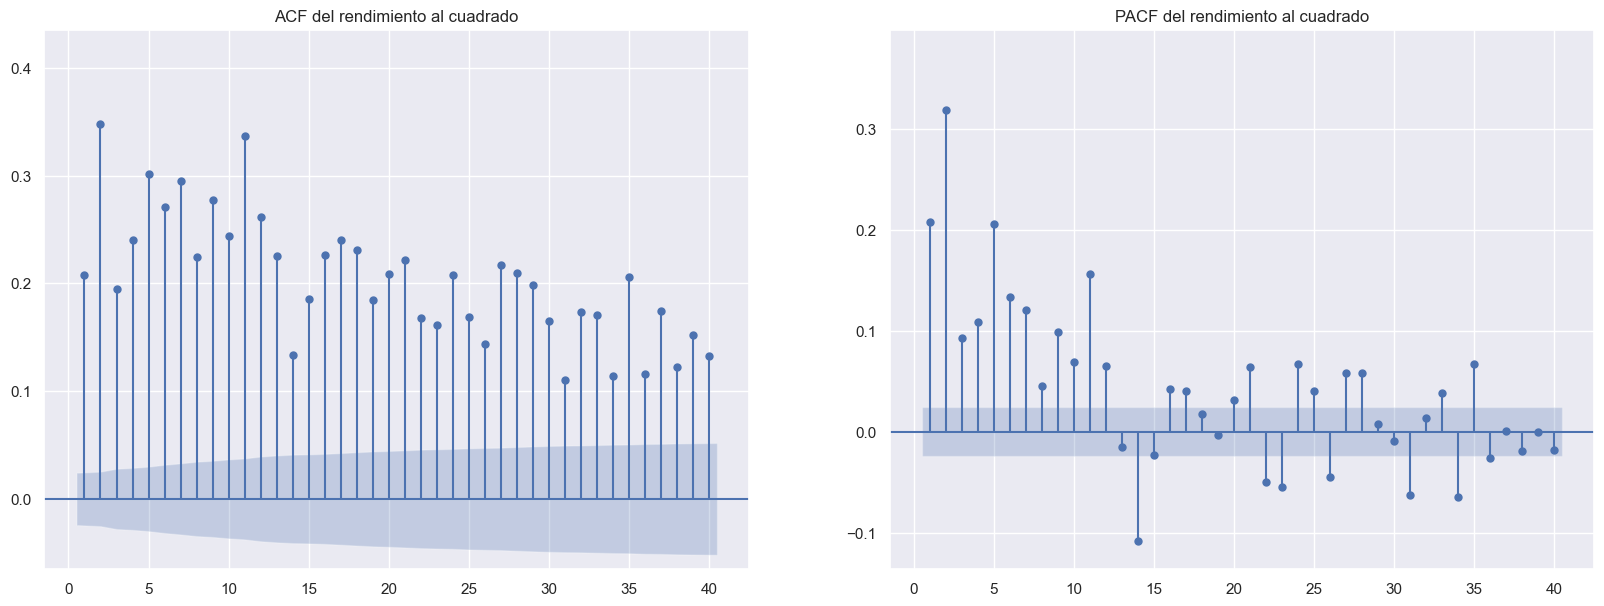

In [35]:
plt.rcParams["figure.figsize"] = (20, 7)
fig, ax = plt.subplots(1, 2)

sgt.plot_acf(train_df.spx_vol, ax = ax[0], zero = False, lags = 40, auto_ylims = True, title = "ACF del rendimiento al cuadrado")
sgt.plot_pacf(train_df.spx_vol, ax = ax[1], zero = False, lags = 40, auto_ylims = True, title = "PACF del rendimiento al cuadrado");

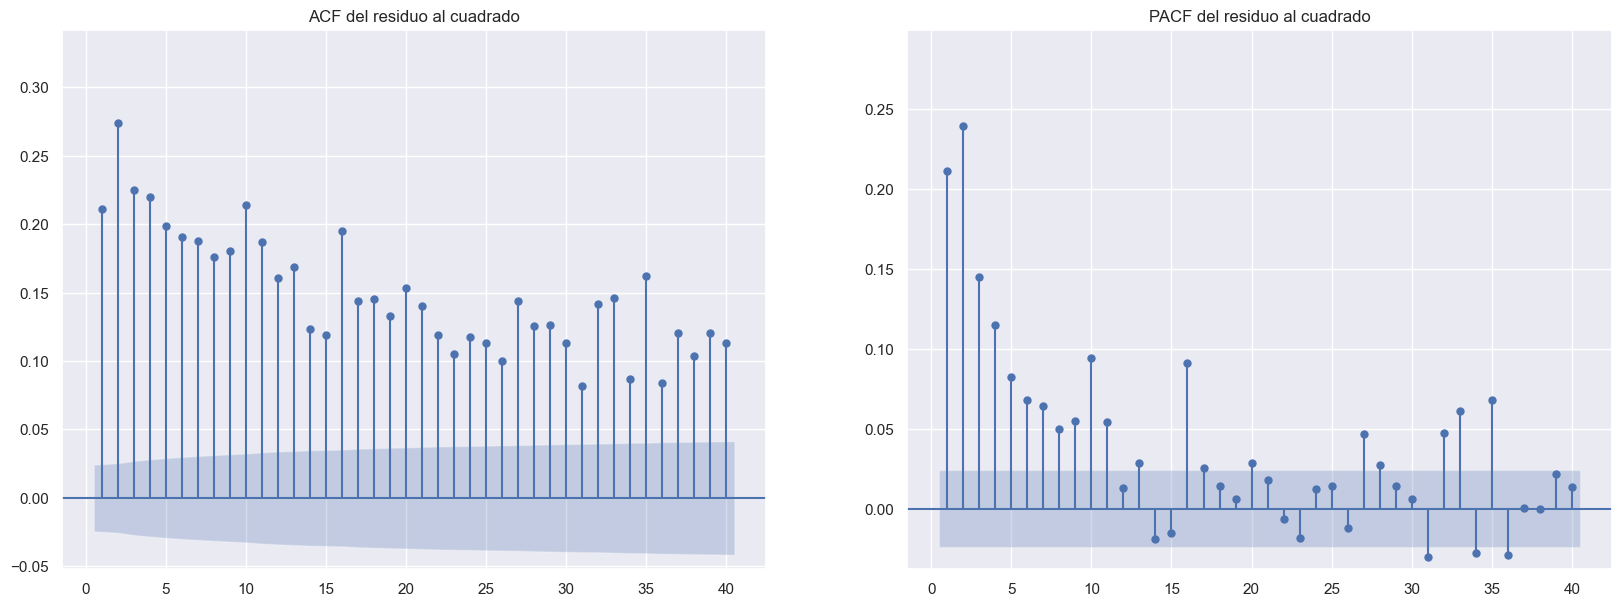

In [36]:
residuo2 = train_res.mul(train_res)

fig, ax = plt.subplots(1, 2)

sgt.plot_acf(residuo2, ax = ax[0], zero = False, lags = 40, auto_ylims = True, title = "ACF del residuo al cuadrado")
sgt.plot_pacf(residuo2, ax = ax[1], zero = False, lags = 40, auto_ylims = True, title = "PACF del residuo al cuadrado");

### Conclusiones de los diagramas

- En ambos casos las autocorrelaciones del cuadrado de la serie son significativas y decaen lentamente durante muchos retardos: hay agrupamiento de la volatilidad (periodos de alta volatilidad seguidos de alta volatilidad).
- La PACF tiene muchos retardos significativos, por lo que un ARCH(p) puro necesitaría un orden alto. Una estructura GARCH, que incluye retardos de la propia varianza, es más parsimoniosa. Partiremos de un GARCH(1,1) y probaremos extensiones asimétricas (EGARCH).

## Modelización de la volatilidad
1. De la rentabilidad de la serie
2. Del residuo

Calculamos primero las volatilidades históricas.

In [37]:
std_daily = train_df.spx_ret.std()
print(f'Volatilidad diaria: {round(std_daily, 2)}%')
print(f'Volatilidad mensual: {round(np.sqrt(21) * std_daily, 2)}%')
print(f'Volatilidad anual: {round(np.sqrt(252) * std_daily, 2)}%')

Volatilidad diaria: 1.13%
Volatilidad mensual: 5.18%
Volatilidad anual: 17.94%


### 1. Volatilidad de la rentabilidad
#### GARCH(1,1)

In [38]:
garchm = arch_model(train_df.spx_ret, p = 1, q = 1, mean = 'constant', vol = 'GARCH', dist = 'normal')
gm_result = garchm.fit(update_freq = 4)
print(gm_result.summary())

Iteration:      4,   Func. Count:     29,   Neg. LLF: 8733.134738014134
Iteration:      8,   Func. Count:     54,   Neg. LLF: 8978.951147199059
Iteration:     12,   Func. Count:     75,   Neg. LLF: 8634.582874315089
Optimization terminated successfully    (Exit mode 0)
            Current function value: 8634.582874314474
            Iterations: 12
            Function evaluations: 75
            Gradient evaluations: 12
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                spx_ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -8634.58
Distribution:                  Normal   AIC:                           17277.2
Method:            Maximum Likelihood   BIC:                           17304.3
                                        No. Observations:                 6517
Date:                M

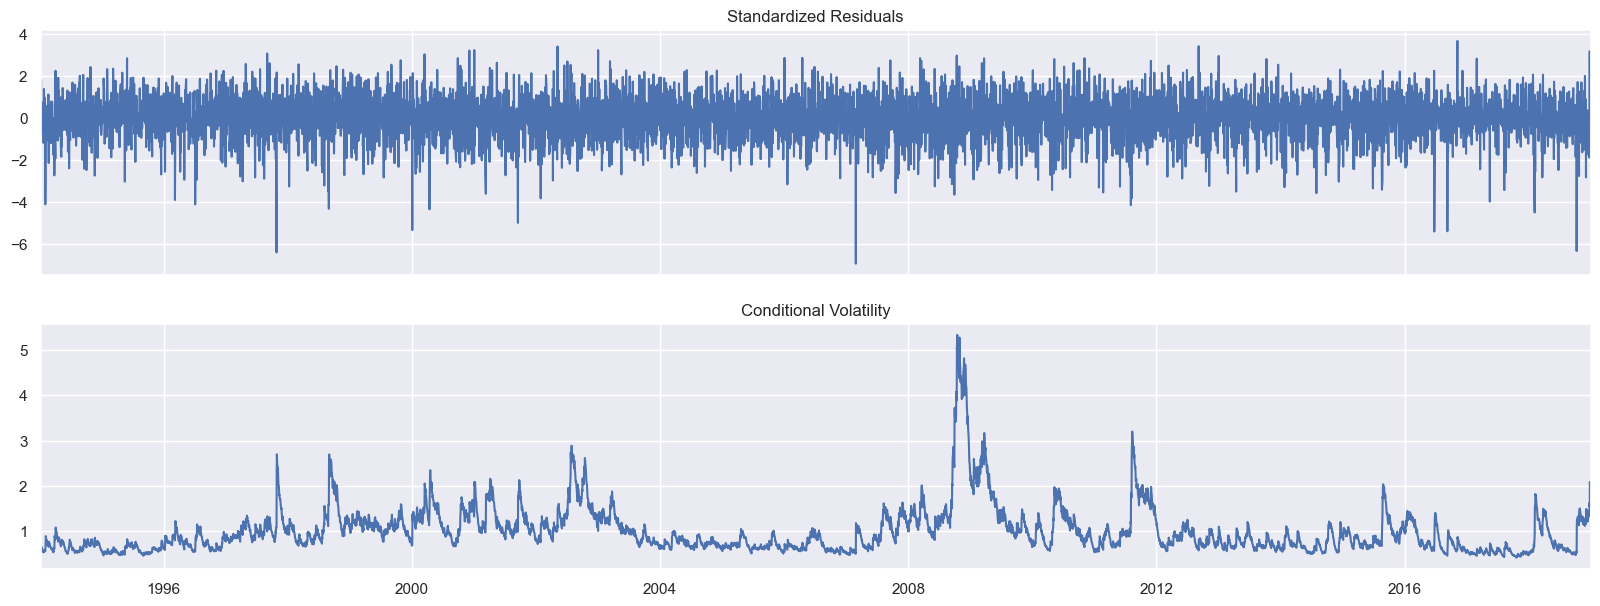

In [39]:
gm_result.plot()
plt.show()

Todos los coeficientes son significativos (p-valor < 0.05) y alpha + beta ≈ 0.99, cercano a 1: la volatilidad es muy persistente. Los rendimientos bursátiles suelen reaccionar de forma asimétrica (las caídas aumentan más la volatilidad que las subidas), así que probamos un EGARCH, que contempla ese efecto con el parámetro gamma.

#### EGARCH(1,1,1)

In [40]:
garchm = arch_model(train_df.spx_ret, p = 1, q = 1, o = 1, mean = 'constant', vol = 'EGARCH', dist = 'normal')
gm_result = garchm.fit(update_freq = 4)
print(gm_result.summary())

Iteration:      4,   Func. Count:     39,   Neg. LLF: 855553428872.5973
Iteration:      8,   Func. Count:     70,   Neg. LLF: 8489.671809555228
Optimization terminated successfully    (Exit mode 0)
            Current function value: 8489.671808633353
            Iterations: 9
            Function evaluations: 76
            Gradient evaluations: 9
                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                spx_ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -8489.67
Distribution:                  Normal   AIC:                           16989.3
Method:            Maximum Likelihood   BIC:                           17023.3
                                        No. Observations:                 6517
Date:                Mon, Oct 05 2026   Df Residuals:                     6516
Time:            

#### EGARCH(2,2,1)

In [41]:
garchm2 = arch_model(train_df.spx_ret, p = 2, q = 1, o = 2, mean = 'constant', vol = 'EGARCH', dist = 'normal')
gm_result2 = garchm2.fit(update_freq = 4)
print(gm_result2.summary())

Iteration:      4,   Func. Count:     47,   Neg. LLF: 12291343548593.959
Iteration:      8,   Func. Count:     93,   Neg. LLF: 49267.12817112093
Iteration:     12,   Func. Count:    126,   Neg. LLF: 8464.607446945472
Optimization terminated successfully    (Exit mode 0)
            Current function value: 8464.60744293574
            Iterations: 14
            Function evaluations: 141
            Gradient evaluations: 14
                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                spx_ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -8464.61
Distribution:                  Normal   AIC:                           16943.2
Method:            Maximum Likelihood   BIC:                           16990.7
                                        No. Observations:                 6517
Date:                

In [42]:
resumen = pd.DataFrame({
    "AIC": [arch_model(train_df.spx_ret, p = 1, q = 1).fit(disp = 'off').aic, gm_result.aic, gm_result2.aic],
    "BIC": [arch_model(train_df.spx_ret, p = 1, q = 1).fit(disp = 'off').bic, gm_result.bic, gm_result2.bic]},
    index = ["GARCH(1,1)", "EGARCH(1,1,1)", "EGARCH(2,2,1)"])
resumen

,AIC,BIC
"GARCH(1,1)",17277.165749,17304.294426
"EGARCH(1,1,1)",16989.343617,17023.254464
"EGARCH(2,2,1)",16943.214886,16990.690072


Los EGARCH mejoran claramente el AIC y el BIC del GARCH(1,1). En ambos, gamma[1] es significativo y negativo: las caídas del índice aumentan más la volatilidad que las subidas de la misma magnitud (efecto apalancamiento). El EGARCH(2,2,1) tiene el menor AIC y BIC; aunque omega y alpha[1] no son significativos (p-valor > 0.05), el resto de coeficientes sí lo son. Comprobamos la calidad con el residuo estandarizado: el p-valor del ARCH test es > 0.05 en los dos EGARCH (y también en el GARCH(1,1)), por lo que ya no queda heterocedasticidad.

In [43]:
for nombre, res in [("EGARCH(1,1,1)", gm_result), ("EGARCH(2,2,1)", gm_result2)]:
    lm_test = het_arch(res.std_resid.dropna())
    print(f"{nombre} -> ARCH test: LM = {lm_test[0]:.4f}, p-valor LM = {lm_test[1]:.4f}, p-valor F = {lm_test[3]:.4f}")

EGARCH(1,1,1) -> ARCH test: LM = 14.5863, p-valor LM = 0.1479, p-valor F = 0.1479
EGARCH(2,2,1) -> ARCH test: LM = 10.2879, p-valor LM = 0.4156, p-valor F = 0.4159


### 2. Volatilidad del residuo
#### GARCH(1,1)

In [44]:
garchr = arch_model(train_res, p = 1, q = 1, mean = 'constant', vol = 'GARCH', dist = 'normal')
gr_result = garchr.fit(update_freq = 4)
print(gr_result.summary())

Iteration:      4,   Func. Count:     25,   Neg. LLF: 25176.702367112477
Iteration:      8,   Func. Count:     47,   Neg. LLF: 25016.699021536682
Iteration:     12,   Func. Count:     78,   Neg. LLF: 1385434.1063031899
Iteration:     16,   Func. Count:    112,   Neg. LLF: 25239.457399494506
Positive directional derivative for linesearch    (Exit mode 8)
            Current function value: 25016.656163102365
            Iterations: 22
            Function evaluations: 136
            Gradient evaluations: 18
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    spx   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -25016.7
Distribution:                  Normal   AIC:                           50041.3
Method:            Maximum Likelihood   BIC:                           50068.4
             

C:\Users\maren\AppData\Local\Temp\ipykernel_10804\4034896735.py:2: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  gr_result = garchr.fit(update_freq = 4)


#### EGARCH(1,1,1)

In [45]:
garchr = arch_model(train_res, p = 1, q = 1, o = 1, mean = 'constant', vol = 'EGARCH', dist = 'normal')
gr_result = garchr.fit(update_freq = 4)
print(gr_result.summary())

Iteration:      4,   Func. Count:     40,   Neg. LLF: 6063581945067.586
Iteration:      8,   Func. Count:     72,   Neg. LLF: 24929.225828780414
Iteration:     12,   Func. Count:     96,   Neg. LLF: 24929.056018800737
Optimization terminated successfully    (Exit mode 0)
            Current function value: 24929.056016154947
            Iterations: 14
            Function evaluations: 107
            Gradient evaluations: 14
                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                    spx   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -24929.1
Distribution:                  Normal   AIC:                           49868.1
Method:            Maximum Likelihood   BIC:                           49902.0
                                        No. Observations:                 6516
Date:             

#### EGARCH(2,2,1)

In [46]:
garchr2 = arch_model(train_res, p = 2, q = 1, o = 2, mean = 'constant', vol = 'EGARCH', dist = 'normal')
gr_result2 = garchr2.fit(update_freq = 4)
print(gr_result2.summary())

Iteration:      4,   Func. Count:     48,   Neg. LLF: 31276353261.1458
Iteration:      8,   Func. Count:     91,   Neg. LLF: 170661134366.6213
Iteration:     12,   Func. Count:    127,   Neg. LLF: 24903.289437384345
Iteration:     16,   Func. Count:    159,   Neg. LLF: 24903.287980444566
Optimization terminated successfully    (Exit mode 0)
            Current function value: 24903.287980444566
            Iterations: 17
            Function evaluations: 166
            Gradient evaluations: 17
                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                    spx   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -24903.3
Distribution:                  Normal   AIC:                           49820.6
Method:            Maximum Likelihood   BIC:                           49868.1
                          

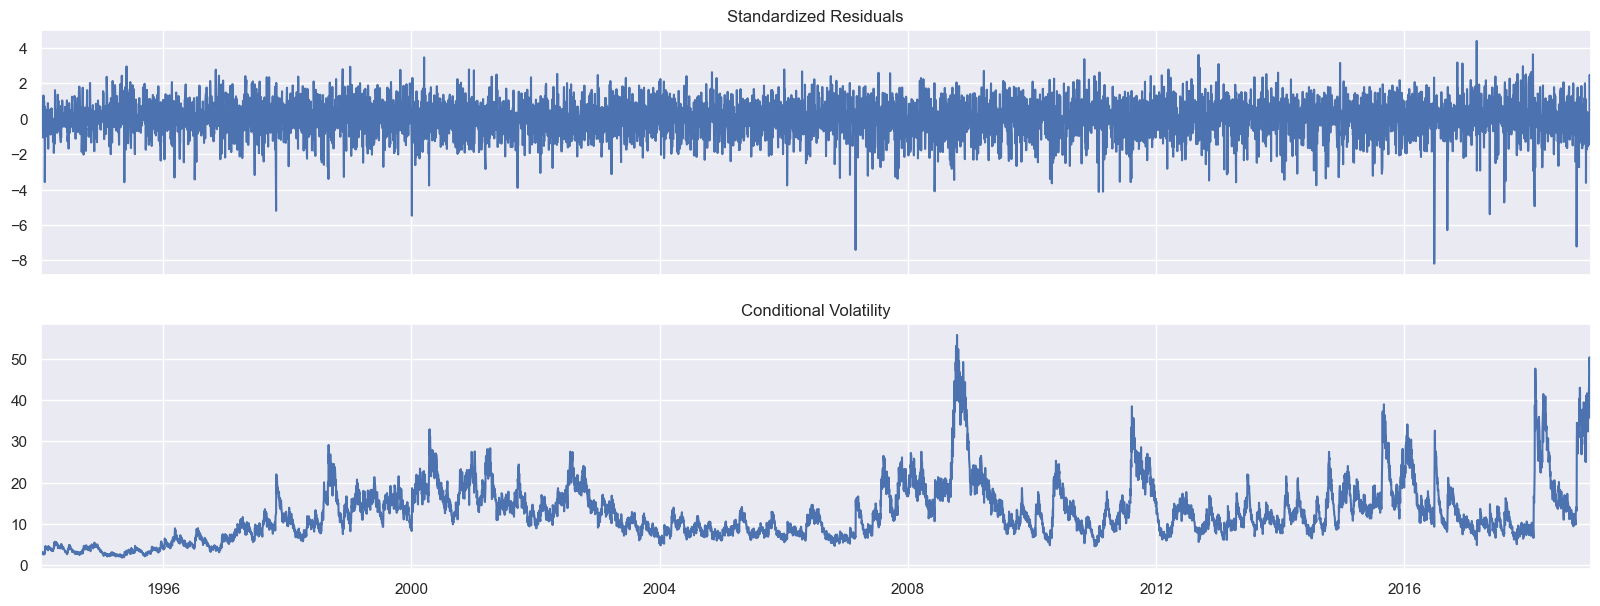

In [47]:
gr_result2.plot()
plt.show()

In [48]:
for nombre, res in [("GARCH(1,1)", arch_model(train_res, p = 1, q = 1).fit(disp = 'off')), ("EGARCH(1,1,1)", gr_result), ("EGARCH(2,2,1)", gr_result2)]:
    lm_test = het_arch(res.std_resid.dropna())
    print(f"{nombre} -> AIC = {res.aic:.1f}, BIC = {res.bic:.1f}, p-valor ARCH test = {lm_test[1]:.4f}")

GARCH(1,1) -> AIC = 50041.3, BIC = 50068.4, p-valor ARCH test = 0.0007
EGARCH(1,1,1) -> AIC = 49868.1, BIC = 49902.0, p-valor ARCH test = 0.0732
EGARCH(2,2,1) -> AIC = 49820.6, BIC = 49868.1, p-valor ARCH test = 0.0571


C:\Users\maren\AppData\Local\Temp\ipykernel_10804\537763307.py:1: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  for nombre, res in [("GARCH(1,1)", arch_model(train_res, p = 1, q = 1).fit(disp = 'off')), ("EGARCH(1,1,1)", gr_result), ("EGARCH(2,2,1)", gr_result2)]:


Aquí la diferencia es más clara que con la rentabilidad: el GARCH(1,1) no elimina la heterocedasticidad (p-valor del ARCH test < 0.05) mientras que los EGARCH sí (p-valor > 0.05) y además tienen mejor AIC/BIC. El gamma es de nuevo significativo y negativo. En el EGARCH(2,2,1) alpha[1] no es significativo, pero es el de menor AIC/BIC. Nos quedamos con el EGARCH(2,2,1) para la predicción en ambos casos.

## Predicción de la volatilidad

Predecimos un paso hacia delante la varianza de cada día del conjunto de test (2019), reajustando el modelo cada día con una ventana creciente (*expanding*) y con una ventana fija (*rolling*).

In [49]:
def predecir(modelo, serie, fija = False):
    index = serie.index
    start_loc = 0
    end_loc = np.where(index >= '2019-01-01')[0].min()
    n = len(serie) - end_loc
    forecasts = {}
    for i in range(n):
        first = start_loc + i if fija else start_loc
        res = modelo.fit(first_obs = first, last_obs = i + end_loc, disp = 'off')
        temp = res.forecast(horizon = 1, reindex = True).variance
        fcast = temp.iloc[i + end_loc - 1]
        forecasts[fcast.name] = fcast
    return pd.DataFrame(forecasts).T

# Rentabilidad
modelo_ret = arch_model(data.spx_ret, p = 2, q = 1, o = 2, mean = 'constant', vol = 'EGARCH', dist = 'normal')
var_ret_exp = predecir(modelo_ret, data.spx_ret)
var_ret_fix = predecir(modelo_ret, data.spx_ret, fija = True)

# Residuo
modelo_res = arch_model(residuo, p = 2, q = 1, o = 2, mean = 'constant', vol = 'EGARCH', dist = 'normal')
var_res_exp = predecir(modelo_res, residuo)
var_res_fix = predecir(modelo_res, residuo, fija = True)
print('Done!')

KeyboardInterrupt: 

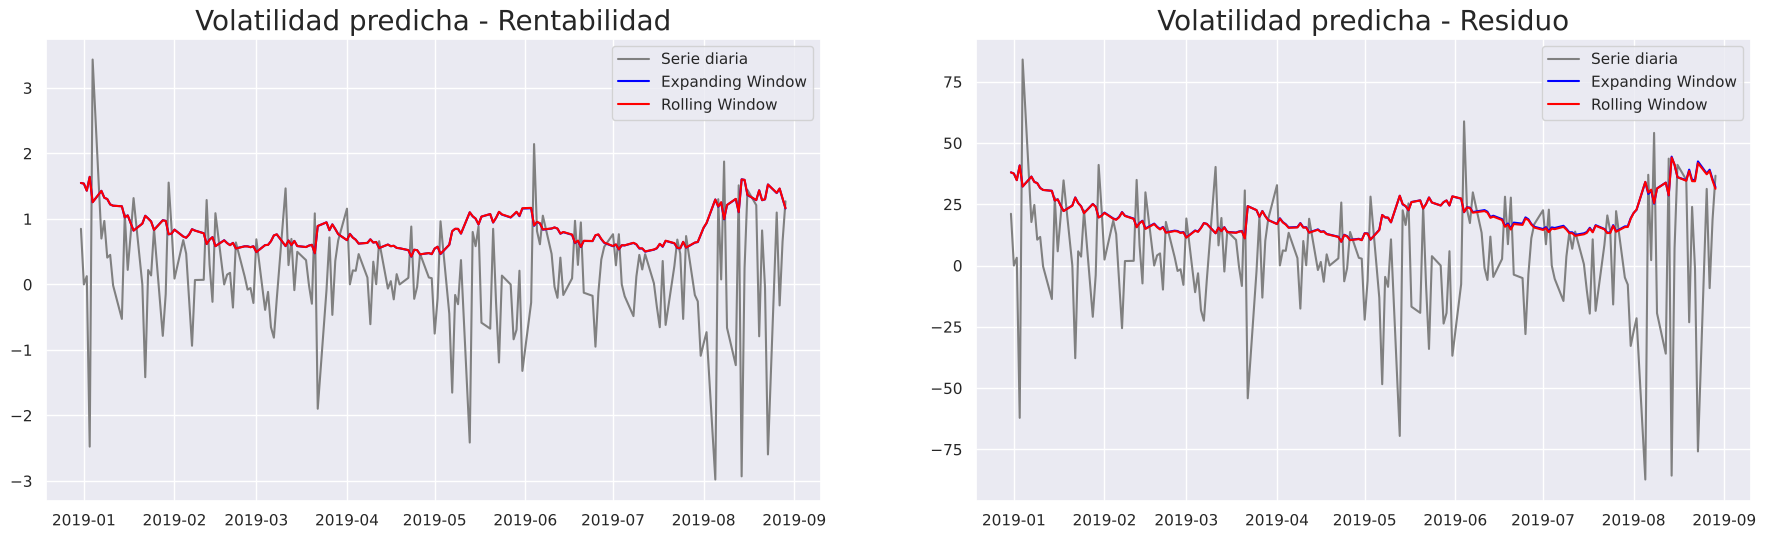

In [ ]:
fig, ax = plt.subplots(1, 2, figsize = (22, 6))

for a, serie, exp, fix, titulo in [(ax[0], data.spx_ret, var_ret_exp, var_ret_fix, "Rentabilidad"),
                                    (ax[1], residuo, var_res_exp, var_res_fix, "Residuo")]:
    a.plot(serie.loc[exp.index], color = 'grey', label = 'Serie diaria')
    a.plot(np.sqrt(exp), color = 'blue', label = 'Expanding Window')
    a.plot(np.sqrt(fix), color = 'red', label = 'Rolling Window')
    a.set_title(f"Volatilidad predicha - {titulo}", size = 20)
    a.legend()
plt.show()

Evaluamos la calidad de la predicción comparando la varianza predicha con la varianza observada (cuadrado de la serie centrada en su media).

In [ ]:
def evaluate(observation, forecast):
    mae = mean_absolute_error(observation, forecast)
    print('Mean Absolute Error (MAE): {:.3g}'.format(mae))
    mse = mean_squared_error(observation, forecast)
    print('Mean Squared Error (MSE): {:.3g}'.format(mse))
    return mae, mse

In [ ]:
var_obs_ret = data.spx_ret.sub(data.spx_ret.mean()).pow(2)[var_ret_exp.index]
var_obs_res = residuo.sub(residuo.mean()).pow(2)[var_res_exp.index]

print("--- Rentabilidad: ventana expanding ---");  evaluate(var_obs_ret, var_ret_exp);
print("--- Rentabilidad: ventana rolling ---");    evaluate(var_obs_ret, var_ret_fix);
print("--- Residuo: ventana expanding ---");       evaluate(var_obs_res, var_res_exp);
print("--- Residuo: ventana rolling ---");         evaluate(var_obs_res, var_res_fix);

--- Rentabilidad: ventana expanding ---
Mean Absolute Error (MAE): 0.791
Mean Squared Error (MSE): 2.12
--- Rentabilidad: ventana rolling ---
Mean Absolute Error (MAE): 0.792
Mean Squared Error (MSE): 2.12
--- Residuo: ventana expanding ---
Mean Absolute Error (MAE): 562
Mean Squared Error (MSE): 1.2e+06
--- Residuo: ventana rolling ---
Mean Absolute Error (MAE): 559
Mean Squared Error (MSE): 1.2e+06


### Conclusiones
- Tanto el rendimiento como el residuo presentan agrupamiento de volatilidad, y el efecto ARCH desaparece tras ajustar un EGARCH.
- La asimetría (gamma[1] < 0 y significativo) indica que la volatilidad reacciona más a las caídas que a las subidas del índice.
- Las dos ventanas (expanding y rolling) dan errores muy similares, porque con más de 6000 observaciones de entrenamiento añadir o quitar un día apenas cambia los parámetros.
- Las métricas del residuo están en unidades de puntos del índice al cuadrado y las de la rentabilidad en %², por lo que no son comparables entre sí.